<a href="https://colab.research.google.com/github/Daudi-Zacharia/MSc_Data_Science/blob/main/Thesis/Segmentation/quantitative_d2_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# INFO

**No-reference quality analysis of the U-Net lung masks on D2 (4200 images).**

D2 has no ground-truth masks, so every predicted mask is judged by its own shape
rather than against a reference. A correct lung mask is roughly two solid blobs;
a failed one breaks into scattered fragments. This notebook turns "TB images
segment worse than Normal images" into a measured, testable claim.

Pipeline, model and transforms are the ones from **Part 5: UNET 2** of
`Segmentation_Unet_Full.ipynb` — same `seg_unet_2.pth` checkpoint, same
224x224 resize, same ImageNet normalization. Nothing about the segmentation is
new here; only the measurement is.

**Contents**

1. Configuration and imports
2. Data setup — the whole of D2 in a flat `Images/{tb,no_tb}` folder
3. Per-mask metrics (`n_components`, `largest2_frac`, `total_area_frac`, `is_clean`)
4. U-Net loading and mask generation over all 4200 images
5. Aggregation — summary table, outliers
6. Statistical test — Mann-Whitney U, TB vs Normal
7. Qualitative figures — 2 examples per class, saved for the manuscript

# 1. CONFIGURATION AND IMPORTS

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install kagglehub -q
!pip install openpyxl -q

In [3]:
import os
import shutil
import time

import numpy as np
import pandas as pd
import PIL
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2 as T

from scipy import ndimage
from scipy.stats import mannwhitneyu

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

# --- paths -----------------------------------------------------------------
path_segmentation = '/content/drive/MyDrive/MSc Data Science/Thesis/Codes/segmentation'
path_model = os.path.join(path_segmentation, 'seg_unet_2.pth')

IMAGES_DIR = './Images'                 # flat folder: Images/tb, Images/no_tb
FIG_DIR = './figures_d2_mask_quality'   # where the manuscript figures are written

# --- analysis settings -----------------------------------------------------
BATCH_SIZE = 64
PROGRESS_EVERY = 5                      # print progress every N batches

# a mask counts as "clean" if it is at most two blobs that hold essentially
# all of the mask area
CLEAN_MAX_COMPONENTS = 2
CLEAN_MIN_LARGEST2 = 0.95

CLASS_NAMES = {0: 'Normal', 1: 'TB'}    # matches the no_tb / tb folders

os.makedirs(FIG_DIR, exist_ok=True)

Device: cuda


# 2. DATA SETUP

`create_images_folder_4200` is the function from `Segmentation_Unet_Full.ipynb`
(Part 5, "4200 dataset"). It copies the whole dataset into a flat
`Images/{tb,no_tb}` folder — no train/val/test split, because this analysis
covers all 4200 images and only needs the class label.

The vestigial 80/10/10 ratio block from the original has been dropped: it only
printed split sizes and never touched the folders it creates, so keeping it here
would print numbers that have nothing to do with this analysis.

In [4]:
import kagglehub

path_rahman = kagglehub.dataset_download("tawsifurrahman/tuberculosis-tb-chest-xray-dataset")
print("Path to dataset files:", path_rahman)

Using Colab cache for faster access to the 'tuberculosis-tb-chest-xray-dataset' dataset.
Path to dataset files: /kaggle/input/tuberculosis-tb-chest-xray-dataset


In [5]:
def create_images_folder_4200(path, base_dir=IMAGES_DIR):
    """Copies every D2 image into base_dir/{tb,no_tb}. Returns the two id lists."""

    tb_md = pd.read_excel(os.path.join(path, 'TB_Chest_Radiography_Database',
                                       'Tuberculosis.metadata.xlsx'))
    no_tb_md = pd.read_excel(os.path.join(path, 'TB_Chest_Radiography_Database',
                                          'Normal.metadata.xlsx'))

    img_id1 = list(tb_md['FILE NAME'])
    img_id0 = list(no_tb_md['FILE NAME'])

    print(f'# of TB images: {len(img_id1)}')
    print(f'# of Normal images: {len(img_id0)}')
    print(f'Total: {len(img_id1) + len(img_id0)}')

    for klas in ['tb', 'no_tb']:
        os.makedirs(os.path.join(base_dir, klas), exist_ok=True)

    path_tb_images = os.path.join(path, 'TB_Chest_Radiography_Database', 'Tuberculosis')
    path_no_tb_images = os.path.join(path, 'TB_Chest_Radiography_Database', 'Normal')

    print('Copying images...')
    for i in img_id1:
        str_i = str(i) + '.png'
        shutil.copy(src=os.path.join(path_tb_images, str_i),
                    dst=os.path.join(base_dir, 'tb', str_i))

    for i in img_id0:
        str_i = str(i) + '.png'
        shutil.copy(src=os.path.join(path_no_tb_images, str_i),
                    dst=os.path.join(base_dir, 'no_tb', str_i))

    print(f'Successfully created {base_dir}/tb and {base_dir}/no_tb')
    return img_id1, img_id0


img_id1, img_id0 = create_images_folder_4200(path_rahman)

# sanity check on the folder contents
for klas in ['tb', 'no_tb']:
    print(f'{klas:>6}: {len(os.listdir(os.path.join(IMAGES_DIR, klas)))} files')

# of TB images: 700
# of Normal images: 3500
Total: 4200
Copying images...
Successfully created ./Images/tb and ./Images/no_tb
    tb: 700 files
 no_tb: 3500 files


# 3. PER-MASK METRICS

Each predicted binary mask (1 = lung) is reduced to four numbers:

| metric | meaning |
|---|---|
| `n_components` | connected components, 8-connectivity |
| `largest2_frac` | area of the two biggest components / total mask area |
| `total_area_frac` | mask pixels / image pixels |
| `is_clean` | `n_components <= 2` **and** `largest2_frac >= 0.95` |

A perfect lung mask scores `n_components = 2`, `largest2_frac = 1.0`. Fragments
push the count up and the fraction down. Empty masks have no shape to measure, so
`largest2_frac` is `NaN` and they are counted separately.

In [6]:
# 8-connectivity: pixels touching at a corner count as the same component.
# (scipy's default is 4-connectivity, which would inflate n_components.)
CONNECTIVITY_8 = np.ones((3, 3), dtype=int)


def mask_metrics(mask):
    """Shape metrics for one predicted binary mask.

    mask: 2-D array, non-zero where the model predicted lung.
    Returns a dict with n_components, largest2_frac, total_area_frac, is_clean.
    """
    total_px = mask.size
    area = int(np.count_nonzero(mask))

    # empty mask: no components, and largest2_frac would be 0/0
    if area == 0:
        return {'n_components': 0,
                'largest2_frac': np.nan,
                'total_area_frac': 0.0,
                'is_clean': False}

    labelled, n_components = ndimage.label(mask, structure=CONNECTIVITY_8)

    # component sizes, dropping label 0 (background)
    sizes = np.bincount(labelled.ravel())[1:]
    # with a single component this sums to the whole mask, giving exactly 1.0
    largest2_frac = float(np.sort(sizes)[-2:].sum() / area)

    return {'n_components': int(n_components),
            'largest2_frac': largest2_frac,
            'total_area_frac': area / total_px,
            'is_clean': bool(n_components <= CLEAN_MAX_COMPONENTS
                             and largest2_frac >= CLEAN_MIN_LARGEST2)}

In [7]:
# quick self-check on hand-made masks, so a silent change in behaviour is visible
_two_blobs = np.zeros((10, 10), dtype=np.uint8)
_two_blobs[1:4, 1:4] = 1        # two well-separated 3x3 blobs, like a good
_two_blobs[6:9, 6:9] = 1        # lung mask: 2 components, largest2_frac 1.0

_speckled = _two_blobs.copy()
_speckled[0, 9] = 1             # one stray pixel: 3 components, frac < 1.0

print('two clean blobs :', mask_metrics(_two_blobs))
print('with one speck  :', mask_metrics(_speckled))
print('empty mask      :', mask_metrics(np.zeros((10, 10), dtype=np.uint8)))

two clean blobs : {'n_components': 2, 'largest2_frac': 1.0, 'total_area_frac': 0.18, 'is_clean': True}
with one speck  : {'n_components': 3, 'largest2_frac': 0.9473684210526315, 'total_area_frac': 0.19, 'is_clean': False}
empty mask      : {'n_components': 0, 'largest2_frac': nan, 'total_area_frac': 0.0, 'is_clean': False}


# 4. U-NET LOADING AND MASK GENERATION

Architecture, checkpoint and preprocessing are copied from Part 5 of
`Segmentation_Unet_Full.ipynb`. Masks are scored as they come off the GPU rather
than written to disk — the analysis only needs the four numbers per image.

In [8]:
from torchvision.models import vgg16_bn


# CONV AND UP_CONV LAYERS
def conv(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )


def up_conv(in_channels, out_channels):
    return nn.Sequential(
        nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )


class UNet(nn.Module):
    """VGG16-BN encoder with a symmetric decoder and skip connections."""

    def __init__(self, num_classes=2):
        super().__init__()

        self.encoder = vgg16_bn(weights='DEFAULT').features

        self.block1 = nn.Sequential(*self.encoder[:6])
        self.block2 = nn.Sequential(*self.encoder[6:13])
        self.block3 = nn.Sequential(*self.encoder[13:20])
        self.block4 = nn.Sequential(*self.encoder[20:27])
        self.block5 = nn.Sequential(*self.encoder[27:34])

        self.bottleneck = nn.Sequential(*self.encoder[34:])
        self.conv_bottleneck = conv(512, 1024)   # widen before upsampling

        self.up_conv6 = up_conv(1024, 512)
        self.conv6 = conv(512 + 512, 512)
        self.up_conv7 = up_conv(512, 256)
        self.conv7 = conv(256 + 512, 256)
        self.up_conv8 = up_conv(256, 128)
        self.conv8 = conv(128 + 256, 128)
        self.up_conv9 = up_conv(128, 64)
        self.conv9 = conv(64 + 128, 64)
        self.up_conv10 = up_conv(64, 32)
        self.conv10 = conv(32 + 64, 32)

        self.conv11 = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        # encoder, keeping each stage for the skip connections
        block1 = self.block1(x)          # (64, 224, 224)
        block2 = self.block2(block1)     # (128, 112, 112)
        block3 = self.block3(block2)     # (256, 56, 56)
        block4 = self.block4(block3)     # (512, 28, 28)
        block5 = self.block5(block4)     # (512, 14, 14)

        bottleneck = self.bottleneck(block5)      # (512, 7, 7)
        x = self.conv_bottleneck(bottleneck)      # (1024, 7, 7)

        # decoder: upsample, concatenate the matching encoder stage, convolve
        x = self.conv6(torch.cat([self.up_conv6(x), block5], dim=1))
        x = self.conv7(torch.cat([self.up_conv7(x), block4], dim=1))
        x = self.conv8(torch.cat([self.up_conv8(x), block3], dim=1))
        x = self.conv9(torch.cat([self.up_conv9(x), block2], dim=1))
        x = self.conv10(torch.cat([self.up_conv10(x), block1], dim=1))

        return self.conv11(x)            # (num_classes, 224, 224)


model = UNet(num_classes=2)
model.load_state_dict(torch.load(path_model, map_location=device))
model.to(device)
model.eval()
print(f'Loaded U-Net checkpoint: {path_model}')

Downloading: "https://download.pytorch.org/models/vgg16_bn-6c64b313.pth" to /root/.cache/torch/hub/checkpoints/vgg16_bn-6c64b313.pth


100%|██████████| 528M/528M [00:04<00:00, 136MB/s]


Loaded U-Net checkpoint: /content/drive/MyDrive/MSc Data Science/Thesis/Codes/segmentation/seg_unet_2.pth


In [9]:
class ROI(Dataset):
    """Yields (original, normalized, label, filename) for every image in root_dir.

    Same transforms the segmentation model was evaluated with: resize to
    224x224, scale to [0,1], ImageNet normalization. The un-normalized copy is
    kept for display only.
    """

    def __init__(self, root_dir):
        self.transforms_norm = T.Compose([
            T.Resize((224, 224)),
            T.ToImage(),                              # PIL -> tv2 tensor
            T.ToDtype(torch.float32, scale=True),     # scales to [0, 1]
            T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
        ])

        self.transforms_orig = T.Compose([
            T.Resize((224, 224)),
            T.ToImage(),
            T.ToDtype(torch.float32, scale=True),
        ])

        self.root_dir = root_dir

        im_id0 = os.listdir(os.path.join(self.root_dir, 'no_tb'))
        im_id1 = os.listdir(os.path.join(self.root_dir, 'tb'))

        # (folder, filename, label)
        self.im_data = [('no_tb', f, 0) for f in im_id0]
        self.im_data += [('tb', f, 1) for f in im_id1]

    def __len__(self):
        return len(self.im_data)

    def __getitem__(self, idx):
        folder, im_name, label = self.im_data[idx]
        image = PIL.Image.open(os.path.join(self.root_dir, folder, im_name)).convert('RGB')

        return (self.transforms_orig(image),
                self.transforms_norm(image),
                torch.tensor(label).long(),
                im_name)


td = ROI(IMAGES_DIR)
dl = DataLoader(td, batch_size=BATCH_SIZE)

# the area fractions below are relative to this resolution, so state it
MASK_H, MASK_W = td[0][1].shape[-2:]
print(f'Number of images : {len(td)}')
print(f'Number of batches: {len(dl)}')
print(f'Mask resolution  : {MASK_H} x {MASK_W}  ({MASK_H * MASK_W} pixels per mask)')

Number of images : 4200
Number of batches: 66
Mask resolution  : 224 x 224  (50176 pixels per mask)


In [10]:
def generate_mask_metrics(model, data_loader, device):
    """Runs the U-Net over the whole dataset and scores each predicted mask.

    Masks are measured batch by batch and discarded, so memory stays flat.
    Returns a per-image DataFrame.
    """
    model.to(device)
    model.eval()

    records = []
    start_time = time.time()
    print(f'Segmenting {len(data_loader.dataset)} images in {len(data_loader)} batches...')

    with torch.no_grad():
        for batch_idx, (_, images_norm, labels, names) in enumerate(data_loader):

            logits = model(images_norm.to(device))
            # class 1 = lung; argmax gives the same binary mask used downstream
            pred_masks = logits.argmax(dim=1).cpu().numpy().astype(np.uint8)

            for i in range(len(pred_masks)):
                records.append({
                    'filename': names[i],
                    'class': CLASS_NAMES[int(labels[i])],
                    **mask_metrics(pred_masks[i]),
                })

            if (batch_idx + 1) % PROGRESS_EVERY == 0:
                done = len(records)
                elapsed = (time.time() - start_time) / 60
                print(f'  batch {batch_idx + 1:>3}/{len(data_loader)} | '
                      f'{done:>4}/{len(data_loader.dataset)} images | '
                      f'{elapsed:.2f} min elapsed')

    total_time = (time.time() - start_time) / 60
    print(f'Done! Total inference time: {total_time:.2f} minutes')

    return pd.DataFrame(records)


# full per-image results, kept around for outlier inspection and spot-checks
df_masks = generate_mask_metrics(model, dl, device)

print()
print(f'Rows: {len(df_masks)}')
display(df_masks.head())

Segmenting 4200 images in 66 batches...
  batch   5/66 |  320/4200 images | 0.16 min elapsed
  batch  10/66 |  640/4200 images | 0.28 min elapsed
  batch  15/66 |  960/4200 images | 0.42 min elapsed
  batch  20/66 | 1280/4200 images | 0.54 min elapsed
  batch  25/66 | 1600/4200 images | 0.68 min elapsed
  batch  30/66 | 1920/4200 images | 0.81 min elapsed
  batch  35/66 | 2240/4200 images | 0.97 min elapsed
  batch  40/66 | 2560/4200 images | 1.11 min elapsed
  batch  45/66 | 2880/4200 images | 1.23 min elapsed
  batch  50/66 | 3200/4200 images | 1.37 min elapsed
  batch  55/66 | 3520/4200 images | 1.49 min elapsed
  batch  60/66 | 3840/4200 images | 1.63 min elapsed
  batch  65/66 | 4160/4200 images | 1.75 min elapsed
Done! Total inference time: 1.77 minutes

Rows: 4200


,filename,class,n_components,largest2_frac,total_area_frac,is_clean
0,Normal-1374.png,Normal,2,1.0,0.306063,True
1,Normal-2663.png,Normal,2,1.0,0.270986,True
2,Normal-1088.png,Normal,2,1.0,0.202168,True
3,Normal-363.png,Normal,2,1.0,0.250678,True
4,Normal-1410.png,Normal,2,1.0,0.286731,True


In [18]:
df_masks[df_masks['class']=='Normal'].describe().round(3)

,n_components,largest2_frac,total_area_frac
count,3500.000,3499.000,3500.000
mean,2.687,0.997,0.246
std,1.275,0.012,0.061
min,0.000,0.692,0.000
25%,2.000,0.999,0.209
50%,2.000,1.000,0.246
75%,3.000,1.000,0.287
max,20.000,1.000,0.448


In [19]:
df_masks[df_masks['class']=='TB'].describe().round(3)

,n_components,largest2_frac,total_area_frac
count,700.000,564.000,700.000
mean,4.117,0.977,0.183
std,3.996,0.053,0.138
min,0.000,0.511,0.000
25%,2.000,0.986,0.024
50%,3.000,0.999,0.207
75%,6.000,1.000,0.295
max,28.000,1.000,0.480


# 5. AGGREGATION

`df_masks` holds one row per image and stays available for spot-checks. The
summary table below is the headline result.

In [11]:
def summarise_by_class(df, classes=('Normal', 'TB')):
    """Per-class summary of the mask-shape metrics."""
    rows = []
    for klass in classes:
        g = df[df['class'] == klass]
        rows.append({
            'Class': klass,
            'n': len(g),
            # mean/sd/median of the component count
            'mean_components': g['n_components'].mean(),
            'sd_components': g['n_components'].std(),
            'median_components': g['n_components'].median(),
            # NaN (empty masks) is skipped by pandas here
            'mean_largest2_frac': g['largest2_frac'].mean(),
            'sd_largest2_frac': g['largest2_frac'].std(),
            'mean_total_area_frac': g['total_area_frac'].mean(),
            'sd_total_area_frac': g['total_area_frac'].std(),
            'pct_clean': 100 * g['is_clean'].mean(),
            'n_empty_masks': int((g['total_area_frac'] == 0).sum()),
        })
    return pd.DataFrame(rows).set_index('Class')


summary = summarise_by_class(df_masks)

print(f'Mask-shape quality on D2, {MASK_H}x{MASK_W} masks '
      f'(clean = at most {CLEAN_MAX_COMPONENTS} components holding '
      f'>= {CLEAN_MIN_LARGEST2:.0%} of the area)')
display(summary.round(3))

Mask-shape quality on D2, 224x224 masks (clean = at most 2 components holding >= 95% of the area)


,n,mean_components,sd_components,median_components,mean_largest2_frac,sd_largest2_frac,mean_total_area_frac,sd_total_area_frac,pct_clean,n_empty_masks
Class,,,,,,,,,,
Normal,3500,2.687,1.275,2.0,0.997,0.012,0.246,0.061,63.371,1
TB,700,4.117,3.996,3.0,0.977,0.053,0.183,0.138,24.571,136


In [12]:
# The 10 most fragmented masks: smallest share of area in the two biggest blobs.
worst10 = (df_masks.dropna(subset=['largest2_frac'])
                   .sort_values(['largest2_frac', 'n_components'],
                                ascending=[True, False])
                   .head(10))

print('10 most fragmented masks')
display(worst10[['filename', 'class', 'n_components',
                 'largest2_frac', 'total_area_frac', 'is_clean']].round(4))

# The 10 cleanest. largest2_frac saturates at 1.0 for a great many masks, so
# ties are broken by the lower component count.
best10 = (df_masks.dropna(subset=['largest2_frac'])
                  .sort_values(['largest2_frac', 'n_components'],
                               ascending=[False, True])
                  .head(10))

print('10 cleanest masks')
display(best10[['filename', 'class', 'n_components',
                'largest2_frac', 'total_area_frac', 'is_clean']].round(4))

# empty masks, if any, are excluded from both listings above
n_empty = int((df_masks['total_area_frac'] == 0).sum())
print(f'Empty masks excluded from the two listings: {n_empty}')

10 most fragmented masks


,filename,class,n_components,largest2_frac,total_area_frac,is_clean
3992,Tuberculosis-661.png,TB,17,0.5110,0.1284,False
3809,Tuberculosis-619.png,TB,8,0.6416,0.1712,False
4152,Tuberculosis-354.png,TB,8,0.6818,0.0004,False
946,Normal-2241.png,Normal,6,0.6920,0.0890,False
3621,Tuberculosis-620.png,TB,10,0.7022,0.1089,False
3783,Tuberculosis-454.png,TB,8,0.7339,0.0245,False
4073,Tuberculosis-680.png,TB,6,0.7623,0.0345,False
3528,Tuberculosis-326.png,TB,22,0.7675,0.1585,False
1334,Normal-993.png,Normal,14,0.7739,0.1908,False
4079,Tuberculosis-669.png,TB,6,0.7846,0.0013,False


10 cleanest masks


,filename,class,n_components,largest2_frac,total_area_frac,is_clean
1123,Normal-2964.png,Normal,1,1.0,0.0002,True
2149,Normal-395.png,Normal,1,1.0,0.0858,True
3132,Normal-2849.png,Normal,1,1.0,0.0223,True
3520,Tuberculosis-194.png,TB,1,1.0,0.0050,True
3583,Tuberculosis-109.png,TB,1,1.0,0.1557,True
3590,Tuberculosis-370.png,TB,1,1.0,0.0000,True
3601,Tuberculosis-315.png,TB,1,1.0,0.0584,True
3672,Tuberculosis-568.png,TB,1,1.0,0.0077,True
3701,Tuberculosis-275.png,TB,1,1.0,0.0572,True
3709,Tuberculosis-209.png,TB,1,1.0,0.2054,True


Empty masks excluded from the two listings: 137


# 6. STATISTICAL TEST

Component counts are small integers with a long right tail, so a t-test would be
the wrong tool. The Mann-Whitney U test compares the two distributions by rank
and assumes nothing about their shape.

Two-sided p-values are reported as the headline (that is what a reviewer will
expect). The one-sided result for the directional claim — TB masks are *more*
fragmented — is printed underneath.

In [13]:
def mannwhitney_report(df, column, higher_is_worse):
    """Mann-Whitney U on `column`, TB vs Normal, with both p-values printed."""
    g = df.dropna(subset=[column])
    tb = g.loc[g['class'] == 'TB', column]
    normal = g.loc[g['class'] == 'Normal', column]

    u_two, p_two = mannwhitneyu(tb, normal, alternative='two-sided')

    # the directional claim: TB masks are more fragmented, i.e. higher component
    # counts but lower largest2_frac
    alt = 'greater' if higher_is_worse else 'less'
    u_one, p_one = mannwhitneyu(tb, normal, alternative=alt)

    dropped = len(df) - len(g)

    print(f'--- {column}: TB (n={len(tb)}) vs Normal (n={len(normal)}) ---')
    if dropped:
        print(f'{dropped} row(s) dropped as NaN (empty masks)')
    print(f'median  TB = {tb.median():.4f} | Normal = {normal.median():.4f}')
    print(f'mean    TB = {tb.mean():.4f} | Normal = {normal.mean():.4f}')
    print(f'two-sided: U = {u_two:.1f}, p = {p_two:.3e}')
    print(f'one-sided (TB {alt} than Normal): U = {u_one:.1f}, p = {p_one:.3e}')
    print()

    return {'metric': column, 'U_two_sided': u_two, 'p_two_sided': p_two,
            'U_one_sided': u_one, 'p_one_sided': p_one}


# more components = worse; higher largest2_frac = better
stats_components = mannwhitney_report(df_masks, 'n_components', higher_is_worse=True)
stats_largest2 = mannwhitney_report(df_masks, 'largest2_frac', higher_is_worse=False)

display(pd.DataFrame([stats_components, stats_largest2]).set_index('metric'))

--- n_components: TB (n=700) vs Normal (n=3500) ---
median  TB = 3.0000 | Normal = 2.0000
mean    TB = 4.1171 | Normal = 2.6874
two-sided: U = 1420180.0, p = 1.469e-13
one-sided (TB greater than Normal): U = 1420180.0, p = 7.347e-14

--- largest2_frac: TB (n=564) vs Normal (n=3499) ---
137 row(s) dropped as NaN (empty masks)
median  TB = 0.9989 | Normal = 1.0000
mean    TB = 0.9773 | Normal = 0.9971
two-sided: U = 600379.5, p = 6.147e-63
one-sided (TB less than Normal): U = 600379.5, p = 3.074e-63



,U_two_sided,p_two_sided,U_one_sided,p_one_sided
metric,,,,
n_components,1420180.0,1.469355e-13,1420180.0,7.346775e-14
largest2_frac,600379.5,6.147178e-63,600379.5,3.073589e-63


# 7. QUALITATIVE FIGURES

Two examples per class, four figures in total:

- **typical** — the mask whose `n_components` and `largest2_frac` sit closest to
  that class's medians. The median is used rather than the mean so a handful of
  badly fragmented masks cannot drag the choice towards an outlier. Distance is
  measured in standard deviations so the two metrics contribute comparably.
- **worst case** — the lowest `largest2_frac` in that class.

Each figure has three panels: original X-ray, predicted mask, and mask overlaid
on the original. Files land in `FIG_DIR` at 300 dpi.

In [14]:
def _scale(series):
    """Standard deviation to normalise a distance by; 1.0 if it is degenerate."""
    s = series.std()
    return float(s) if np.isfinite(s) and s > 0 else 1.0


def pick_examples(df, klass):
    """Returns (typical_row, worst_row) for one class."""
    g = df[(df['class'] == klass)].dropna(subset=['largest2_frac'])

    med_n = g['n_components'].median()
    med_f = g['largest2_frac'].median()

    # combined distance from the class medians, in standard deviations
    distance = ((g['n_components'] - med_n).abs() / _scale(g['n_components'])
                + (g['largest2_frac'] - med_f).abs() / _scale(g['largest2_frac']))

    typical = g.loc[distance.idxmin()]
    worst = g.loc[g['largest2_frac'].idxmin()]

    print(f'{klass}: medians n_components = {med_n:.1f}, '
          f'largest2_frac = {med_f:.4f}')
    print(f'  typical -> {typical["filename"]} '
          f'(n_components={typical["n_components"]}, '
          f'largest2_frac={typical["largest2_frac"]:.4f})')
    print(f'  worst   -> {worst["filename"]} '
          f'(n_components={worst["n_components"]}, '
          f'largest2_frac={worst["largest2_frac"]:.4f})')

    return typical, worst


def render_example(row, tag, out_path):
    """3-panel figure: original, predicted mask, overlay. Saves and displays it."""
    folder = 'tb' if row['class'] == 'TB' else 'no_tb'
    img_path = os.path.join(IMAGES_DIR, folder, row['filename'])

    # reuse the dataset's own transforms so preprocessing matches the run above
    pil_img = PIL.Image.open(img_path).convert('RGB')
    x_orig = td.transforms_orig(pil_img)
    x_norm = td.transforms_norm(pil_img)

    with torch.no_grad():
        pred = model(x_norm.unsqueeze(0).to(device)).argmax(dim=1).squeeze(0).cpu().numpy()

    orig_np = x_orig.permute(1, 2, 0).numpy()

    fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))

    axes[0].imshow(orig_np)
    axes[0].set_title('Original')

    axes[1].imshow(pred, cmap='gray', vmin=0, vmax=1)
    axes[1].set_title('Predicted mask')

    axes[2].imshow(orig_np)
    # masked_where hides the background so only the lung region is tinted
    axes[2].imshow(np.ma.masked_where(pred == 0, pred),
                   cmap='autumn', alpha=0.4, vmin=0, vmax=1)
    axes[2].set_title('Overlay')

    for ax in axes:
        ax.axis('off')

    fig.suptitle(f'{row["class"]} - {tag}\n{row["filename"]}  |  '
                 f'n_components = {row["n_components"]}, '
                 f'largest2_frac = {row["largest2_frac"]:.3f}',
                 fontsize=12)

    fig.tight_layout()
    fig.savefig(out_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f'saved -> {out_path}')
    return out_path

Normal: medians n_components = 2.0, largest2_frac = 1.0000
  typical -> Normal-1374.png (n_components=2, largest2_frac=1.0000)
  worst   -> Normal-2241.png (n_components=6, largest2_frac=0.6920)


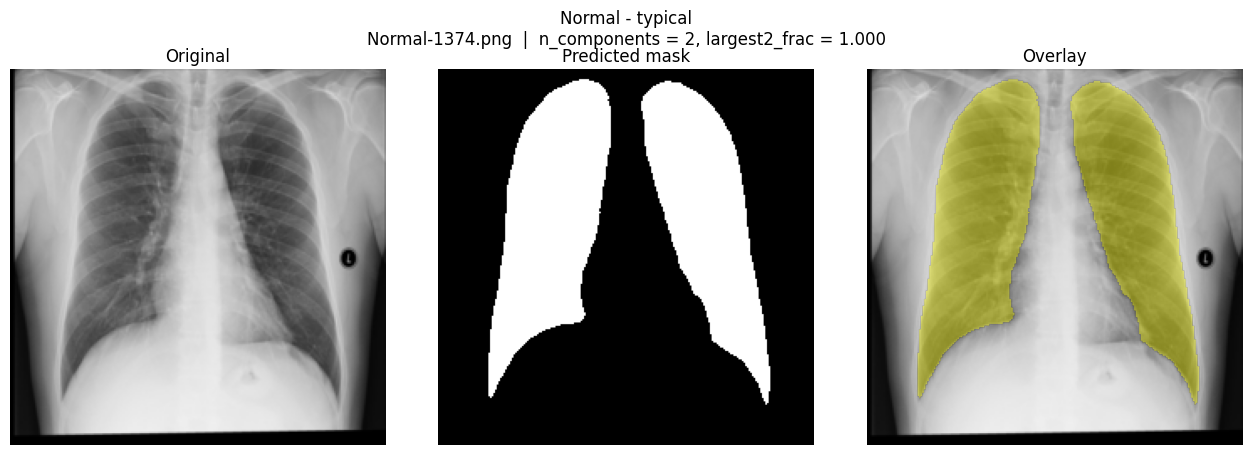

saved -> ./figures_d2_mask_quality/normal_typical.png


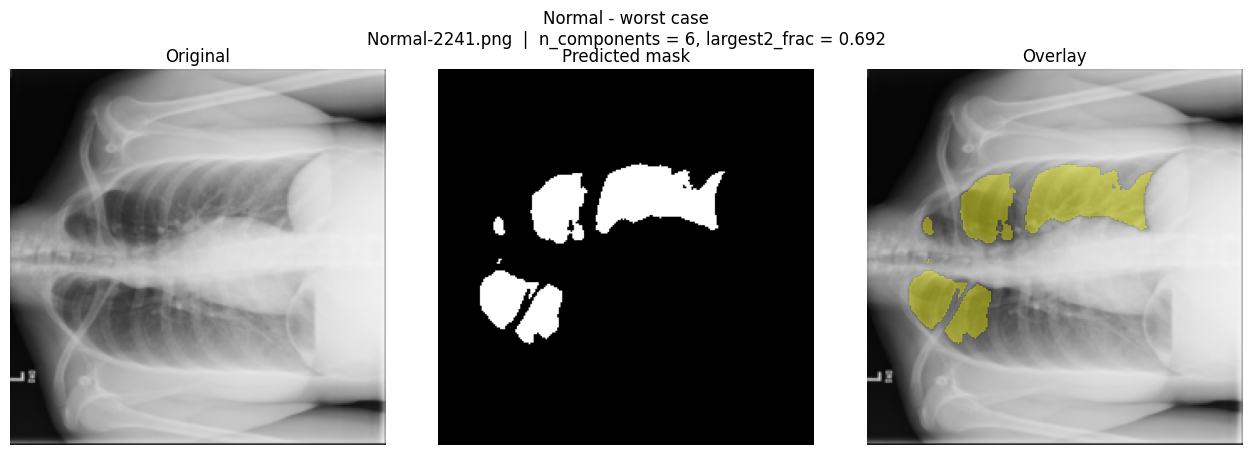

saved -> ./figures_d2_mask_quality/normal_worst.png

TB: medians n_components = 4.0, largest2_frac = 0.9989
  typical -> Tuberculosis-273.png (n_components=4, largest2_frac=0.9989)
  worst   -> Tuberculosis-661.png (n_components=17, largest2_frac=0.5110)


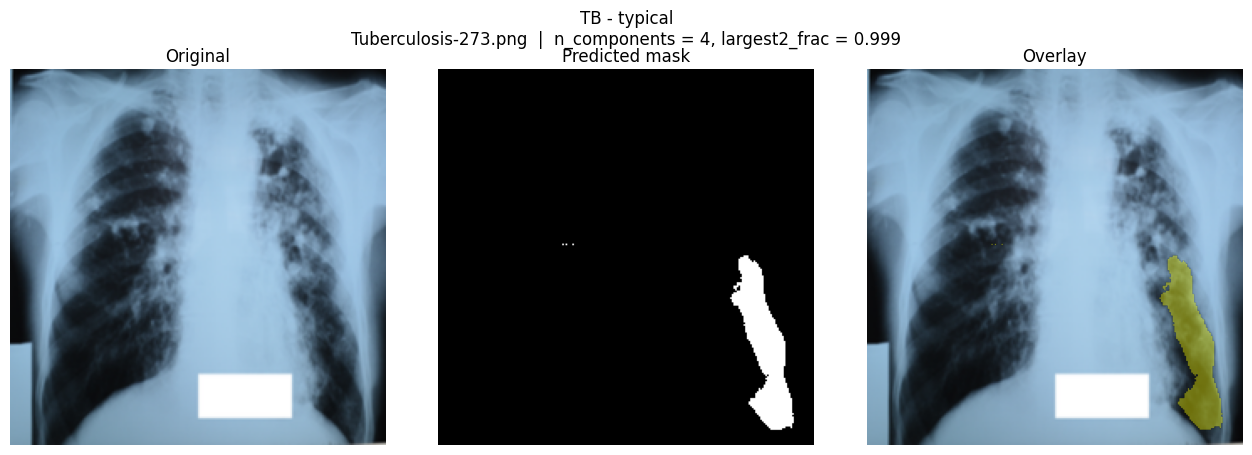

saved -> ./figures_d2_mask_quality/tb_typical.png


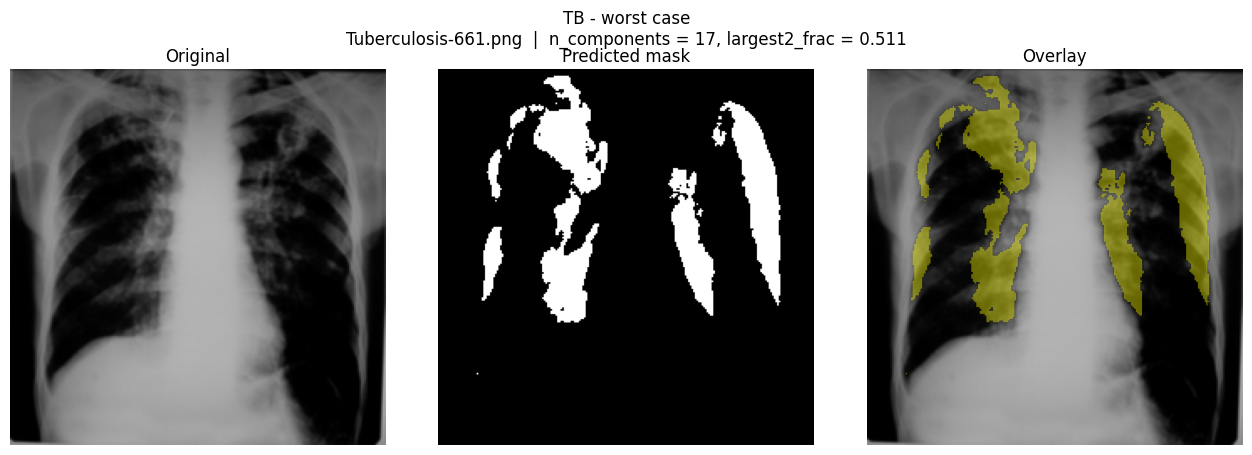

saved -> ./figures_d2_mask_quality/tb_worst.png

Figures written:
  ./figures_d2_mask_quality/normal_typical.png
  ./figures_d2_mask_quality/normal_worst.png
  ./figures_d2_mask_quality/tb_typical.png
  ./figures_d2_mask_quality/tb_worst.png


In [15]:
saved_figures = []

for klass in ['Normal', 'TB']:
    typical, worst = pick_examples(df_masks, klass)
    slug = klass.lower()

    saved_figures.append(render_example(
        typical, 'typical', os.path.join(FIG_DIR, f'{slug}_typical.png')))
    saved_figures.append(render_example(
        worst, 'worst case', os.path.join(FIG_DIR, f'{slug}_worst.png')))
    print()

print('Figures written:')
for p in saved_figures:
    print(' ', p)

In [16]:
# Colab wipes the local disk when the session ends. Uncomment to keep the
# figures in Drive alongside the rest of the thesis assets.

# fig_drive_dir = os.path.join(path_segmentation, 'figures_d2_mask_quality')
# os.makedirs(fig_drive_dir, exist_ok=True)
# for p in saved_figures:
#     shutil.copy(p, os.path.join(fig_drive_dir, os.path.basename(p)))
# print(f'Copied {len(saved_figures)} figures to {fig_drive_dir}')

# The per-image table is also worth keeping for the appendix / spot-checks.
# df_masks.to_csv(os.path.join(path_segmentation, 'd2_mask_quality_per_image.csv'),
#                 index=False)